In [1]:
!pip install numpy pandas librosa matplotlib scikit-learn

In [2]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
dataset_path = r"C:\Users\SANKAR GANESH\Dataset\Dataset"

ambulance_folder = os.path.join(dataset_path, "ambulance")
police_folder = os.path.join(dataset_path, "police")

audio_extensions = (".wav", ".mp3", ".flac", ".ogg", ".m4a")

ambulance_files = [
    os.path.join(ambulance_folder, f)
    for f in os.listdir(ambulance_folder)
    if f.lower().endswith(audio_extensions)
]

police_files = [
    os.path.join(police_folder, f)
    for f in os.listdir(police_folder)
    if f.lower().endswith(audio_extensions)
]

print("Ambulance recordings:", len(ambulance_files))
print("Police recordings:", len(police_files))

Ambulance recordings: 400
Police recordings: 454


File: C:\Users\SANKAR GANESH\Dataset\Dataset\ambulance\mixed_sound_1.wav
Sample rate: 44100 Hz
Audio shape: (2, 132300)
Channels: 2
Duration: 3.0 seconds


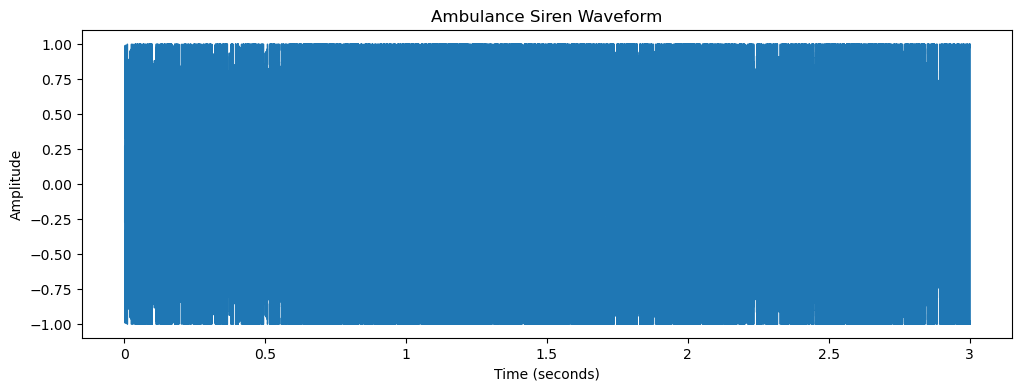

In [4]:
audio_path = ambulance_files[0]
audio, sample_rate = librosa.load(audio_path, sr=None, mono=False)

print("File:", audio_path)
print("Sample rate:", sample_rate, "Hz")
print("Audio shape:", audio.shape)

if audio.ndim == 1:
    duration = len(audio) / sample_rate
    print("Channels: Mono")
else:
    duration = audio.shape[-1] / sample_rate
    print("Channels:", audio.shape[0])

print("Duration:", round(duration, 2), "seconds")

plt.figure(figsize=(12, 4))
if audio.ndim == 1:
    librosa.display.waveshow(audio, sr=sample_rate)
else:
    librosa.display.waveshow(audio[0], sr=sample_rate)
plt.title("Ambulance Siren Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

Dominant frequency: 90.33 Hz


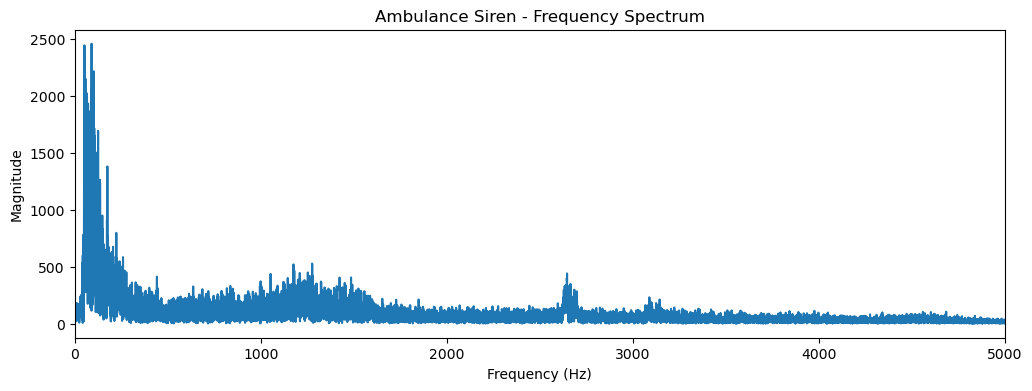

In [5]:
audio, sr = librosa.load(ambulance_files[0], sr=16000, mono=True)

fft = np.fft.rfft(audio)
frequencies = np.fft.rfftfreq(len(audio), 1/sr)
magnitude = np.abs(fft)
magnitude[0] = 0

dominant_frequency = frequencies[np.argmax(magnitude)]
print("Dominant frequency:", round(dominant_frequency, 2), "Hz")

plt.figure(figsize=(12, 4))
plt.plot(frequencies, magnitude)
plt.xlim(0, 5000)
plt.title("Ambulance Siren - Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.show()

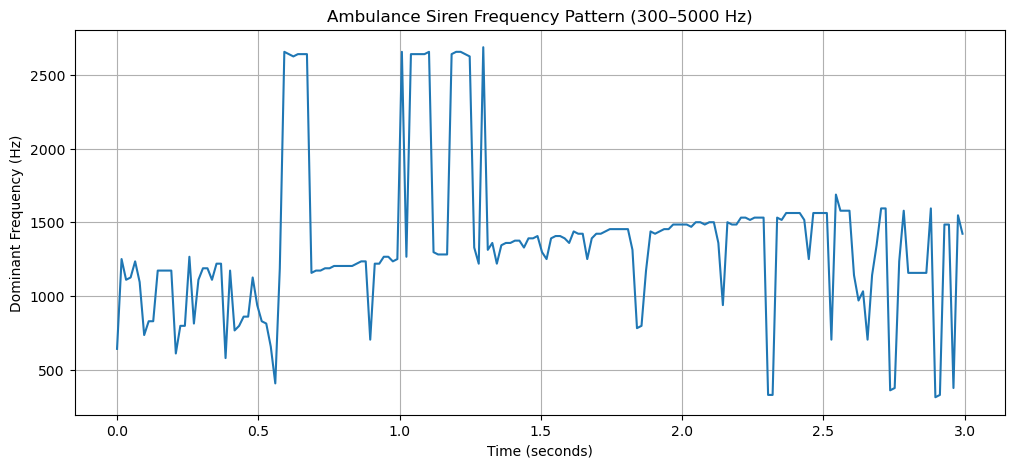

In [7]:
stft = librosa.stft(audio, n_fft=1024, hop_length=256)
magnitude = np.abs(stft)
frequencies = librosa.fft_frequencies(sr=sr, n_fft=1024)

valid = (frequencies >= 300) & (frequencies <= 5000)
filtered_magnitude = magnitude[valid, :]
filtered_frequencies = frequencies[valid]
dominant_freqs = filtered_frequencies[np.argmax(filtered_magnitude, axis=0)]

times = librosa.frames_to_time(np.arange(len(dominant_freqs)), sr=sr, hop_length=256)

plt.figure(figsize=(12, 5))
plt.plot(times, dominant_freqs)
plt.title("Ambulance Siren Frequency Pattern (300–5000 Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Dominant Frequency (Hz)")
plt.grid()
plt.show()

In [8]:
def extract_ambulance_features(file_path):
    audio, sr = librosa.load(file_path, sr=16000, mono=True)

    # --- Dominant frequency contour (siren-specific) ---
    stft = librosa.stft(audio, n_fft=1024, hop_length=256)
    magnitude = np.abs(stft)
    frequencies = librosa.fft_frequencies(sr=sr, n_fft=1024)
    valid = (frequencies >= 300) & (frequencies <= 5000)
    filtered_magnitude = magnitude[valid, :]
    filtered_frequencies = frequencies[valid]
    dominant_freqs = filtered_frequencies[np.argmax(filtered_magnitude, axis=0)]

    mean_freq = np.mean(dominant_freqs)
    min_freq = np.min(dominant_freqs)
    max_freq = np.max(dominant_freqs)
    std_freq = np.std(dominant_freqs)
    freq_range = max_freq - min_freq

    # --- Modulation rate: how fast the siren sweeps (wail vs yelp) ---
    centered = dominant_freqs - mean_freq
    autocorr = np.correlate(centered, centered, mode="full")
    autocorr = autocorr[len(autocorr)//2:]
    if len(autocorr) > 20 and autocorr[0] != 0:
        autocorr = autocorr / autocorr[0]
        peak_lag = np.argmax(autocorr[1:20]) + 1
    else:
        peak_lag = 1
    modulation_strength = np.max(np.abs(np.diff(dominant_freqs)))

    # --- RMS / ZCR (mean + std) ---
    rms_frames = librosa.feature.rms(y=audio)[0]
    zcr_frames = librosa.feature.zero_crossing_rate(audio)[0]

    # --- MFCCs (timbre) ---
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # --- Spectral shape descriptors ---
    centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sr)[0]
    rolloff = librosa.feature.spectral_rolloff(y=audio, sr=sr)[0]
    contrast = librosa.feature.spectral_contrast(y=audio, sr=sr)
    chroma = librosa.feature.chroma_stft(y=audio, sr=sr)

    features = [
        mean_freq, min_freq, max_freq, std_freq, freq_range,
        peak_lag, modulation_strength,
        np.mean(rms_frames), np.std(rms_frames),
        np.mean(zcr_frames), np.std(zcr_frames),
        np.mean(centroid), np.std(centroid),
        np.mean(bandwidth), np.std(bandwidth),
        np.mean(rolloff), np.std(rolloff),
        np.mean(contrast), np.std(contrast),
        np.mean(chroma), np.std(chroma),
    ]
    features.extend(mfcc_mean.tolist())
    features.extend(mfcc_std.tolist())

    return features


feature_names = [
    "mean_frequency", "min_frequency", "max_frequency", "frequency_std", "freq_range",
    "modulation_lag", "modulation_strength",
    "rms_mean", "rms_std",
    "zcr_mean", "zcr_std",
    "centroid_mean", "centroid_std",
    "bandwidth_mean", "bandwidth_std",
    "rolloff_mean", "rolloff_std",
    "contrast_mean", "contrast_std",
    "chroma_mean", "chroma_std",
] + [f"mfcc{i+1}_mean" for i in range(13)] + [f"mfcc{i+1}_std" for i in range(13)]

print("Total features per recording:", len(feature_names))

Total features per recording: 47


In [9]:
ambulance_features = []
for i, file_path in enumerate(ambulance_files):
    try:
        features = extract_ambulance_features(file_path)
        ambulance_features.append(features)
    except Exception as e:
        print("Error:", file_path)
        print(e)

print("Successfully processed:", len(ambulance_features))

Successfully processed: 400


In [10]:
ambulance_df = pd.DataFrame(ambulance_features, columns=feature_names)
ambulance_df["label"] = 0

print("Ambulance dataset created successfully!")
print("Number of recordings:", len(ambulance_df))
print("Number of features:", len(ambulance_df.columns) - 1)
print(ambulance_df.head())

Ambulance dataset created successfully!
Number of recordings: 400
Number of features: 47
   mean_frequency  min_frequency  max_frequency  frequency_std  freq_range  \
0     1361.203457          312.5       2687.500     512.420817    2375.000   
1     1017.536569          312.5       1609.375     414.559596    1296.875   
2      925.531915          312.5       1562.500     481.359790    1250.000   
3     1147.107713          312.5       3109.375     426.819853    2796.875   
4     1071.974734          312.5       1562.500     428.428208    1250.000   

   modulation_lag  modulation_strength  rms_mean   rms_std  zcr_mean  ...  \
0               1             1484.375  0.614114  0.045551  0.118813  ...   
1               1             1296.875  0.552590  0.045933  0.137804  ...   
2               1             1031.250  0.599384  0.115680  0.076302  ...   
3               1             2343.750  0.625391  0.035574  0.135285  ...   
4               1             1187.500  0.606491  0.03613

In [11]:
police_features = []
for file_path in police_files:
    try:
        features = extract_ambulance_features(file_path)
        police_features.append(features)
    except Exception as e:
        print("Error:", file_path)
        print(e)

print("Successfully processed police recordings:", len(police_features))

Successfully processed police recordings: 454


In [12]:
police_df = pd.DataFrame(police_features, columns=feature_names)
police_df["label"] = 1

print("Police dataset created successfully!")
print("Number of recordings:", len(police_df))
print(police_df.head())

Police dataset created successfully!
Number of recordings: 454
   mean_frequency  min_frequency  max_frequency  frequency_std  freq_range  \
0      607.130984        312.500       1140.625     195.625156     828.125   
1      920.046543        312.500       2734.375     448.651318    2421.875   
2      736.452793        328.125       1718.750     241.561142    1390.625   
3      874.002660        312.500       2734.375     415.715529    2421.875   
4     1020.528590        312.500       3515.625     847.302844    3203.125   

   modulation_lag  modulation_strength  rms_mean   rms_std  zcr_mean  ...  \
0               1              718.750  0.604376  0.038916  0.066318  ...   
1               1             2421.875  0.591639  0.036738  0.124429  ...   
2               1              781.250  0.521896  0.096511  0.116923  ...   
3               1             2343.750  0.575408  0.038051  0.091786  ...   
4               1             3187.500  0.640989  0.037394  0.123546  ...   

   mf

In [13]:
full_df = pd.concat([ambulance_df, police_df], ignore_index=True)

print("Combined dataset shape:", full_df.shape)
print("\nClass distribution:")
print(full_df["label"].value_counts())
print("\nMissing values:")
print(full_df.isnull().sum())

Combined dataset shape: (854, 48)

Class distribution:
label
1    454
0    400
Name: count, dtype: int64

Missing values:
mean_frequency         0
min_frequency          0
max_frequency          0
frequency_std          0
freq_range             0
modulation_lag         0
modulation_strength    0
rms_mean               0
rms_std                0
zcr_mean               0
zcr_std                0
centroid_mean          0
centroid_std           0
bandwidth_mean         0
bandwidth_std          0
rolloff_mean           0
rolloff_std            0
contrast_mean          0
contrast_std           0
chroma_mean            0
chroma_std             0
mfcc1_mean             0
mfcc2_mean             0
mfcc3_mean             0
mfcc4_mean             0
mfcc5_mean             0
mfcc6_mean             0
mfcc7_mean             0
mfcc8_mean             0
mfcc9_mean             0
mfcc10_mean            0
mfcc11_mean            0
mfcc12_mean            0
mfcc13_mean            0
mfcc1_std              0
mfc

In [14]:
X = full_df.drop("label", axis=1)
y = full_df["label"]

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (854, 47)
Labels shape: (854,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 683
Testing samples: 171


In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [17]:
rf_param_grid = {
    "n_estimators": [3, 5],
    "max_depth": [None, 4, 6],
    "min_samples_split": [2, 4],
    "class_weight": ["balanced"],
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
    n_jobs=-1,
)
rf_grid.fit(X_train_scaled, y_train)
best_rf = rf_grid.best_estimator_
print("Best RF params:", rf_grid.best_params_)

results = {}
for name, model in [("Random Forest", best_rf)]:
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results[name] = (model, acc)
    print(f"\n{name} Accuracy: {round(acc * 100, 2)} %")
    print(classification_report(y_test, y_pred, target_names=["Ambulance", "Police"]))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

Best RF params: {'class_weight': 'balanced', 'max_depth': 6, 'min_samples_split': 2, 'n_estimators': 5}

Random Forest Accuracy: 80.12 %
              precision    recall  f1-score   support

   Ambulance       0.79      0.79      0.79        80
      Police       0.81      0.81      0.81        91

    accuracy                           0.80       171
   macro avg       0.80      0.80      0.80       171
weighted avg       0.80      0.80      0.80       171

Confusion Matrix:
[[63 17]
 [17 74]]


Cross-val accuracy: 81.40% (+/- 3.39%)


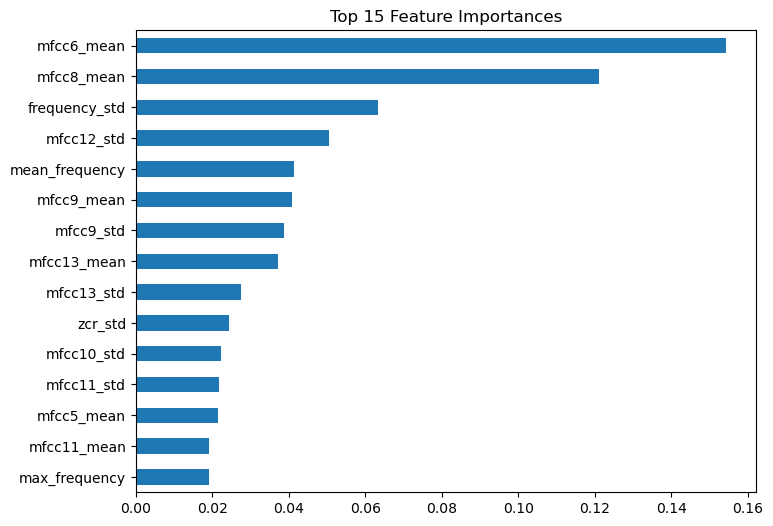

In [18]:
cv_scores = cross_val_score(model if hasattr(model, "feature_importances_") else best_rf,
                             X_train_scaled, y_train, cv=5)
print("Cross-val accuracy: %.2f%% (+/- %.2f%%)" % (cv_scores.mean()*100, cv_scores.std()*100))

if hasattr(model, "feature_importances_"):
    importances = pd.Series(model.feature_importances_, index=feature_names)
    importances.sort_values(ascending=False).head(15).plot(kind="barh", figsize=(8,6))
    plt.title("Top 15 Feature Importances")
    plt.gca().invert_yaxis()
    plt.show()

In [19]:
import joblib, os
joblib.dump(model, "model_size_check.pkl")
print("Model file size:", os.path.getsize("model_size_check.pkl") / 1024, "KB")

Model file size: 31.3837890625 KB
